# Hoya Marketplace Analysis

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)

plt.style.use('default')

In [2]:
df = pd.read_csv("shopee_hoya_clean.csv")

print(df.shape)

df.head()

(420, 11)


,product_name,variety,price,number_sold,location,rating,number_of_reviews,marketplace,scraping_date,product_url,shop_name
0,Hoya Cumigiana,Cumigiana,10000,5,Kab. Lumajang,4.90,497,Shopee,2026-06-11,https://shopee.co.id/product/348755541/8915296529,Ngundang anggrek
1,Hoya Lacunosa Rimbun Bunganya Wangi,Lacunosa,12000,5,Kab. Lumajang,4.93,307,Shopee,2026-06-11,https://shopee.co.id/product/348755541/6579385658,Ngundang anggrek
2,Tanaman Hoya Carnosa Tricolor Atau Crimsom Pri...,Carnosa,34500,3,Kab. Bandung Barat,4.98,84,Shopee,2026-06-11,https://shopee.co.id/product/104126944/6352344959,Shofiflora
3,Sekulen Cluster Hoya Love Varigata Bercabang,Love,27500,7,Kab. Bandung Barat,4.94,48,Shopee,2026-06-11,https://shopee.co.id/product/163019197/2871789...,Kaktus Store
4,Hoya kuning cerah,Kuning,20000,3,Kab. Lumajang,4.88,97,Shopee,2026-06-11,https://shopee.co.id/product/348755541/8787796573,Ngundang anggrek


## Data Cleaning

In [3]:
print(df.info())

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate URLs")
print(
    df.duplicated(
        subset=['product_url']
    ).sum()
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   product_name       420 non-null    object 
 1   variety            420 non-null    object 
 2   price              420 non-null    int64  
 3   number_sold        420 non-null    int64  
 4   location           420 non-null    object 
 5   rating             420 non-null    float64
 6   number_of_reviews  420 non-null    int64  
 7   marketplace        420 non-null    object 
 8   scraping_date      420 non-null    object 
 9   product_url        420 non-null    object 
 10  shop_name          420 non-null    object 
dtypes: float64(1), int64(3), object(7)
memory usage: 36.2+ KB
None

Missing Values
product_name         0
variety              0
price                0
number_sold          0
location             0
rating               0
number_of_reviews    0
marketplace          0
scr

In [4]:
df = df.drop_duplicates(
    subset=['product_url']
)

print(df.shape)

(420, 11)


In [5]:
df['price'] = (
    df['price']
    .astype(str)
    .str.replace('Rp','', regex=False)
    .str.replace('.','', regex=False)
    .str.replace(',','', regex=False)
    .str.strip()
)

df['price'] = pd.to_numeric(
    df['price'],
    errors='coerce'
)

In [6]:
df['price'].describe()

count       420.000000
mean      30565.738095
std       29340.057226
min        1500.000000
25%       12500.000000
50%       24400.000000
75%       35000.000000
max      250000.000000
Name: price, dtype: float64

In [7]:
def clean_sold(x):

    if pd.isna(x):
        return np.nan

    x = str(x).upper().strip()

    x = x.replace("+","")

    x = x.replace(",", ".")

    if "RB" in x:

        try:
            return float(
                x.replace("RB","")
            ) * 1000

        except:
            return np.nan

    try:
        return float(x)

    except:
        return np.nan


df['number_sold'] = (
    df['number_sold']
    .apply(clean_sold)
)

In [8]:
df['number_sold'].describe()

count    420.000000
mean       4.342857
std       16.842995
min        0.000000
25%        1.000000
50%        1.000000
75%        2.000000
max      267.000000
Name: number_sold, dtype: float64

In [9]:
df['rating'] = pd.to_numeric(
    df['rating'],
    errors='coerce'
)

df['number_of_reviews'] = pd.to_numeric(
    df['number_of_reviews'],
    errors='coerce'
)

In [10]:
df['variety'] = (
    df['variety']
    .astype(str)
    .str.strip()
    .str.title()
)

In [11]:
mapping = {

    'Curly':'Compacta',

    'Love':'Kerrii'

}

df['variety'] = (
    df['variety']
    .replace(mapping)
)

In [12]:
df['estimated_revenue'] = (
    df['price']
    *
    df['number_sold']
)

### Create variety dataset

In [13]:
exclude_varieties = [

    'Tidak Teridentifikasi',

    'Bunga',

    'Unknown',

    'Other'

]

df_variety = (
    df[
        ~df['variety'].isin(
            exclude_varieties
        )
    ]
    .copy()
)

print(df.shape)

print(df_variety.shape)

(420, 12)
(376, 12)


### Dataset Overview

In [14]:
summary = pd.DataFrame({

    'Metric':[

        'Total Listings',

        'Total Units Sold',

        'Average Price',

        'Median Price',

        'Average Rating',

        'Total Estimated Revenue'

    ],

    'Value':[

        len(df),

        df['number_sold'].sum(),

        df['price'].mean(),

        df['price'].median(),

        df['rating'].mean(),

        df['estimated_revenue'].sum()

    ]

})

summary

,Metric,Value
0,Total Listings,4.200000e+02
1,Total Units Sold,1.824000e+03
2,Average Price,3.056574e+04
3,Median Price,2.440000e+04
4,Average Rating,4.006976e+00
5,Total Estimated Revenue,4.788714e+07


## Variety Analysis
"Which Hoya varieties are most traded?"

In [15]:
variety_stats = (
    df_variety
    .groupby('variety')
    .agg(
        listings=('product_name','count'),
        sold=('number_sold','sum'),
        avg_price=('price','mean'),
        revenue=('estimated_revenue','sum')
    )
    .sort_values(
        'revenue',
        ascending=False
    )
)

variety_stats.head(20)

,listings,sold,avg_price,revenue
variety,,,,
Compacta,23,324.0,37434.782609,12304000.0
Macrophylla,14,248.0,22728.571429,4329500.0
Carnosa,32,114.0,28961.031250,4163204.0
Wayetii,2,34.0,55000.000000,1710000.0
Archboldiana,3,13.0,113833.333333,1516000.0
Kerrii,20,40.0,25065.000000,1085300.0
Gigas,1,3.0,250000.000000,750000.0
Imperialis,3,6.0,76933.333333,584800.0
Cornosa,8,23.0,25620.625000,506061.0


### Top Varieties by Revenue

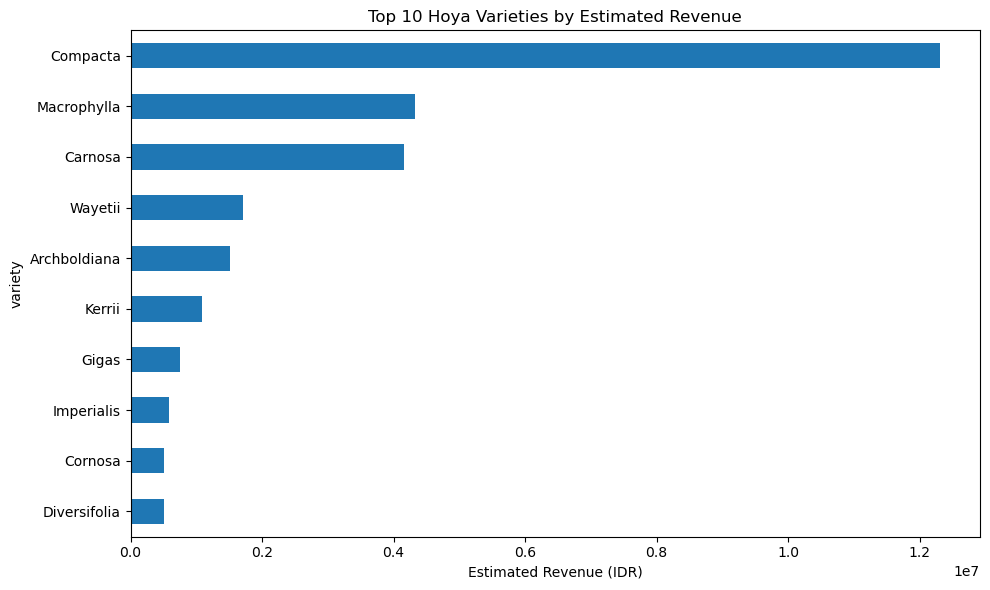

In [16]:
top10 = (
    variety_stats
    .head(10)
    .sort_values(
        'revenue'
    )
)

plt.figure(figsize=(10,6))

top10['revenue'].plot(
    kind='barh'
)

plt.title(
    'Top 10 Hoya Varieties by Estimated Revenue'
)

plt.xlabel(
    'Estimated Revenue (IDR)'
)

plt.tight_layout()

plt.show()

### Top Varieties by Units Sold

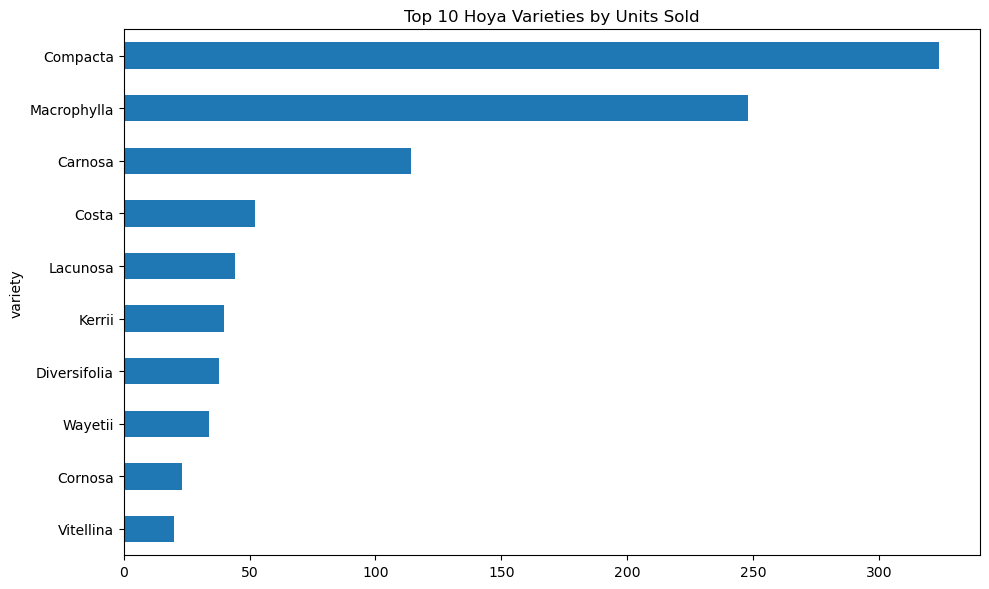

In [24]:
top_sold = (
    df_variety
    .groupby('variety')
    ['number_sold']
    .sum()
    .sort_values(
        ascending=False
    )
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10,6))

top_sold.plot(
    kind='barh'
)

plt.title(
    'Top 10 Hoya Varieties by Units Sold'
)

plt.tight_layout()

plt.show()

## Price Variation Analysis
"How does price vary among Hoya varieties?"

In [18]:
top_varieties = (
    df_variety['variety']
    .value_counts()
    .head(10)
    .index
)

plot_df = (
    df_variety[
        df_variety['variety']
        .isin(top_varieties)
    ]
)

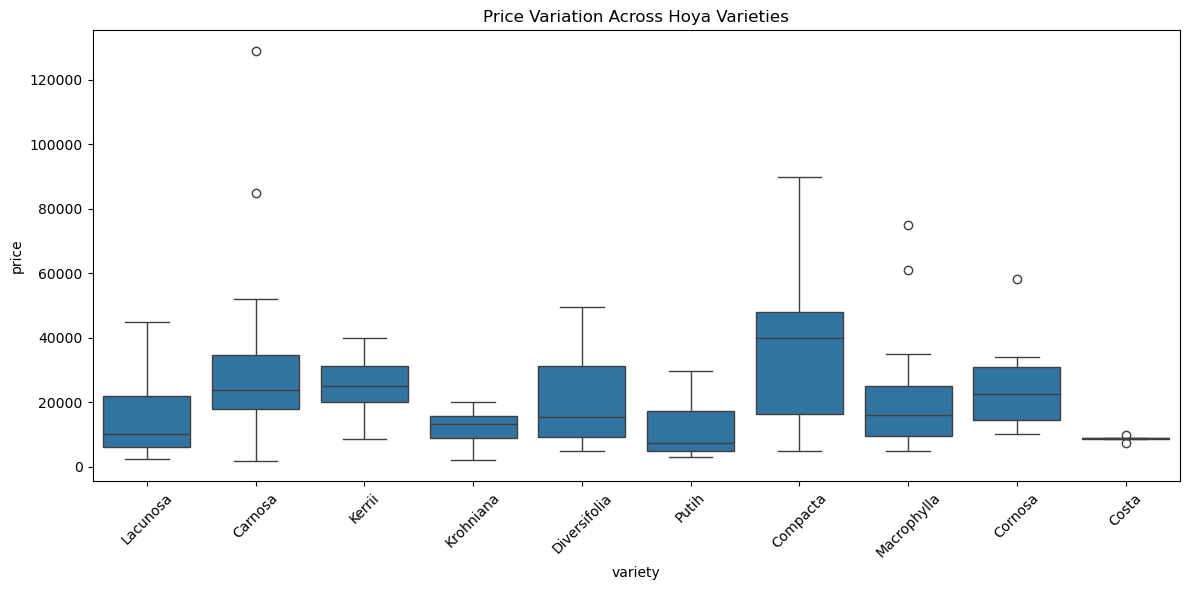

In [19]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=plot_df,
    x='variety',
    y='price'
)

plt.xticks(rotation=45)

plt.title(
    'Price Variation Across Hoya Varieties'
)

plt.tight_layout()

plt.show()

## Location Analysis
"Which regions are most selling Hoya?"

In [20]:
location_stats = (
    df
    .groupby('location')
    .agg(
        listings=('product_name','count'),
        sold=('number_sold','sum'),
        revenue=('estimated_revenue','sum')
    )
    .sort_values(
        'revenue',
        ascending=False
    )
)

location_stats.head(20)

,listings,sold,revenue
location,,,
Kab. Cianjur,21,313.0,12245000.0
Kab. Bandung Barat,56,395.0,8859348.0
Kab. Purworejo,12,201.0,5555000.0
Kab. Gunung Kidul,10,21.0,3250000.0
Kab. Bogor,56,145.0,2738605.0
Kab. Sukabumi,32,67.0,2328500.0
Jakarta Pusat,10,47.0,1889870.0
Bandung,2,27.0,1344974.0
Kab. Mojokerto,33,39.0,1341000.0


### Top Locations by Revenue

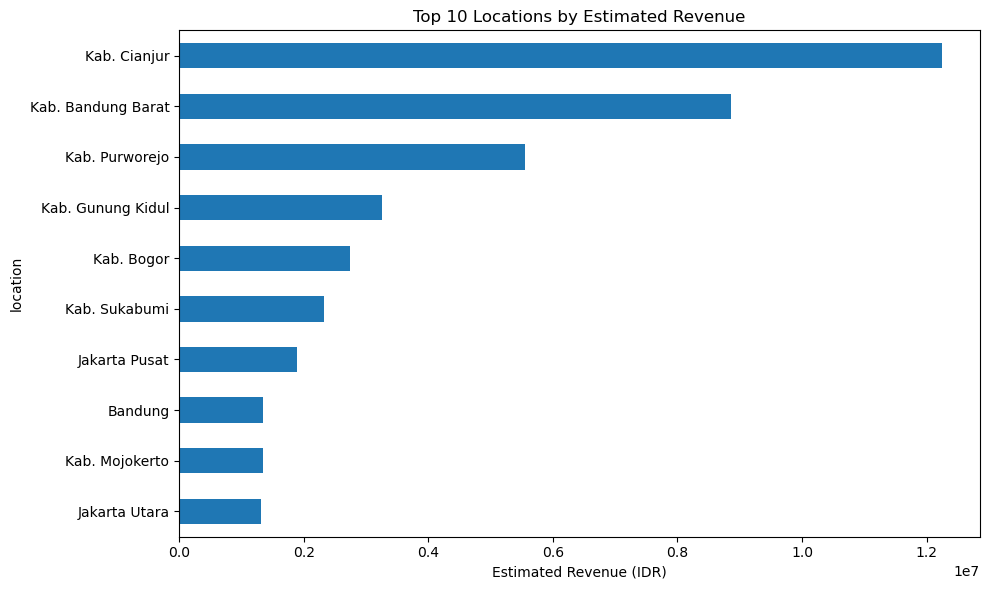

In [21]:
top_loc = (
    location_stats
    .head(10)
    .sort_values(
        'revenue'
    )
)

plt.figure(figsize=(10,6))

top_loc['revenue'].plot(
    kind='barh'
)

plt.title(
    'Top 10 Locations by Estimated Revenue'
)

plt.xlabel(
    'Estimated Revenue (IDR)'
)

plt.tight_layout()

plt.show()